# MC833 · Projeto 3 — Parte 1: Análise Exploratória de Dados (EDA)

**Previsão de tráfego de rede com redes neurais recorrentes** · comparando a Internet de **2007** e de **2024**

## Contexto
Neste trabalho você vai analisar e prever o tráfego de um link real de backbone, medido pelo projeto **MAWI** (WIDE, Japão). Usamos **dois traces de 15 minutos**, ambos de **sábado, 10 de fevereiro, às 14:00 (JST)**, com 17 anos de diferença:

| | 2007 | 2024 |
|---|---|---|
| Trace MAWI | `200702101400` | `202402101400` |

Escolhemos o mesmo dia da semana e o mesmo horário para que as diferenças que você encontrar reflitam, principalmente, **a evolução da Internet** e não o dia ou a hora da medição.

## O que você vai fazer nesta parte
Antes de treinar um modelo, é preciso **conhecer os dados**. Aqui você vai:

1. gerar as **estatísticas descritivas** do throughput (média, desvio-padrão, quartis, mínimo e máximo);
2. produzir **três gráficos**, cada um com **2007 à esquerda e 2024 à direita**, para comparar os dois anos;
3. **comentar** o que viu.

| Entrega | Onde |
|---|---|
| Tabela de estatísticas descritivas | Tarefa T1 |
| Gráfico 1: throughput ao longo do tempo | Exemplo E2 (pronto: use no relatório) |
| Gráfico 2: histogramas do throughput TCP × UDP | Tarefa T2 |
| Gráfico 3: distribuição do tamanho dos pacotes (TCP × UDP) | Tarefa T3 |
| Comentário comparando 2007 e 2024 | Seção 5 |

Esses resultados formam a seção **"Análise exploratória de dados"** do relatório (PDF). Números e gráficos sozinhos não bastam: **explique o que eles significam** em termos de redes.

## Como usar este notebook
* Rode as células em ordem. Os **exemplos** (E1–E3) já estão prontos.
* Complete as células marcadas com `# TODO` nas tarefas T1–T3.
* Salve cada figura para o relatório com `plt.savefig('nome.png', dpi=200, bbox_inches='tight')` logo antes de `plt.show()`.
* **Comente seu código.**

## 1. Setup

In [4]:
import os, sys, json, warnings
from types import SimpleNamespace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
EM_COLAB = 'google.colab' in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

# ============================ CONFIGURAÇÃO ============================
# Pasta que contém uma subpasta por trace (ex.: .../dados/200702101400/200702101400_serie_1s.parquet)
PASTA_DADOS = './dados'
# Os dois traces analisados: sábado, 10/02, às 14:00 (JST) em dois anos distantes
TRACES = {'2007': '200702101400', '2024': '202402101400'}
# ======================================================================

### Funções auxiliares
Não precisa alterá-las. Leia os comentários: elas serão usadas nas tarefas.

In [5]:
# ---------- Estilo dos gráficos: uma cor por ano e uma cor por protocolo, sempre as mesmas ----------
COR = {'2007': '#2a78d6', '2024': '#eb6834'}
COR_PROTO = {'TCP': '#1baf7a', 'UDP': '#4a3aa7', 'ICMP': '#eda100', 'Outro IP': '#8a8a85', 'Não IP': '#c9c8c2'}
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 1.2})

# ---------- Carregamento ----------
def _ler(tid, nome, **kw):
    return pd.read_parquet(os.path.join(PASTA_DADOS, tid, f'{tid}_{nome}.parquet'), **kw)

def carregar(ano):
    """Lê os arquivos pré-processados de um ano e devolve um objeto com um DataFrame por arquivo."""
    tid = TRACES[ano]
    d = SimpleNamespace(ano=ano, id=tid)
    with open(os.path.join(PASTA_DADOS, tid, f'{tid}_resumo.json'), encoding='utf-8') as f:
        d.resumo = json.load(f)          # totais do trace (duração, pacotes, bytes, % por protocolo...)
    d.s10 = _ler(tid, 'serie_10ms')      # série temporal: bytes e pacotes a cada 10 ms, total e por protocolo
    d.tam = _ler(tid, 'hist_tamanhos')   # histograma exato do tamanho dos pacotes (por protocolo)
    return d

# ---------- Séries temporais ----------
BIN_MS = 10   # resolução da série fina (ms)

def reagregar(df, escala_ms, colunas=None):
    """Soma a série fina (10 ms) em intervalos de `escala_ms` ms (múltiplo de 10).
    O último intervalo, se incompleto, é descartado. A coluna t_s é o início do intervalo (s)."""
    fator = int(escala_ms // BIN_MS)
    n = (len(df) // fator) * fator
    cols = colunas or [c for c in df.columns if c not in ('timestamp', 't_s')]
    r = df.iloc[:n][cols].groupby(np.arange(n) // fator).sum()
    r.insert(0, 't_s', r.index.values * escala_ms / 1000)
    return r.reset_index(drop=True)

def mbps(bytes_, escala_ms):
    """bytes em um intervalo de `escala_ms` ms -> throughput em Mbps."""
    return np.asarray(bytes_) * 8 / (escala_ms / 1000) / 1e6

def vazao(ano, escala_ms=1000, coluna='bytes'):
    """throughput (Mbps) de um ano, na escala pedida, como pd.Series indexada pelo tempo (s).
    `coluna` pode ser: bytes (total), bytes_tcp, bytes_udp, bytes_icmp, bytes_outro, bytes_ipv4, bytes_ipv6."""
    r = reagregar(D[ano].s10, escala_ms, [coluna])
    return pd.Series(mbps(r[coluna].values, escala_ms), index=r['t_s'].values, name=f'{coluna} (Mbps)')

## 2. Os dados

Cada trace da MAWI (ponto de coleta **samplepoint-F**) cobre **15 minutos** a partir das 14:00 (horário do Japão). Os pacotes brutos já foram lidos e resumidos em arquivos Parquet; aqui usamos três deles (carregados em `D[ano]`):

| Objeto | O que contém |
|---|---|
| `D[ano].s10` | bytes e pacotes **a cada 10 ms**: total, por TCP/UDP/ICMP/outro e por IPv4/IPv6 |
| `D[ano].tam` | quantos pacotes existem de **cada tamanho**, por protocolo (colunas `tipo`, `tamanho`, `pacotes`) |
| `D[ano].resumo` | totais do trace: duração, nº de pacotes e bytes, throughput médio, % por protocolo |

Você **não** vai trabalhar com os pacotes um a um: a série `s10` já traz o tráfego agregado no tempo, e é a partir dela que `vazao(ano, escala_ms, coluna)` calcula o throughput em Mbps na escala que você pedir.

**Cuidados ao interpretar:**

* O **tamanho do pacote** é o tamanho real no fio. A MAWI corta o payload na captura, então o tamanho *capturado* não serve para medir volume.
* É **um único ponto de medição**, em **um sábado à tarde**, por **15 minutos**: não generalize para "a Internet".
* Os endereços IP já vêm anonimizados pela MAWI; não tente identificar hosts.

In [7]:
D = {ano: carregar(ano) for ano in TRACES}
for ano, d in D.items():
    r = d.resumo
    print(f"{ano}: {r['pacotes'] / 1e6:6.1f} M pacotes | {r['duracao_s']:.0f} s | {r['vazao_media_mbps']:.1f} Mbps")

2007:   14.5 M pacotes | 900 s | 94.3 Mbps
2024:  138.8 M pacotes | 900 s | 1228.9 Mbps


## 3. Exemplos resolvidos

### Exemplo E1 · Visão geral dos dois traces

**Objetivo:** Comparar de uma só vez os totais dos dois anos, a partir do `resumo.json`.

In [8]:
def tabela_resumo():
    linhas = {}
    for ano, d in D.items():
        r = d.resumo
        linhas[ano] = {
            'Início (JST)': r['inicio_jst'][:19],
            'Duração (s)': round(r['duracao_s'], 1),
            'Pacotes (milhões)': round(r['pacotes'] / 1e6, 2),
            'Volume (GB)': round(r['bytes'] / 1e9, 2),
            'Throughput médio (Mbps)': round(r['vazao_media_mbps'], 2),
            'Tamanho médio do pacote (B)': round(r['tamanho_medio'], 1),
            '% bytes TCP': round(100 * r['bytes_por_tipo']['TCP'] / r['bytes'], 1),
            '% bytes UDP': round(100 * r['bytes_por_tipo']['UDP'] / r['bytes'], 1),
            '% pacotes IPv6': round(100 * r['pacotes_ipv6'] / r['pacotes'], 1),
        }
    return pd.DataFrame(linhas)

tabela_resumo()

,2007,2024
Início (JST),2007-02-10 14:00:00,2024-02-10 14:00:00
Duração (s),900.3,899.8
Pacotes (milhões),14.49,138.79
Volume (GB),10.61,138.22
Throughput médio (Mbps),94.3,1228.9
Tamanho médio do pacote (B),732.5,995.9
% bytes TCP,97.2,88.1
% bytes UDP,2.1,7.9
% pacotes IPv6,0.7,9.0


### Exemplo E2 · Gráfico 1 — Throughput ao longo do tempo

**Objetivo:** Ver a série que a LSTM vai tentar prever: o throughput por segundo (em Mbps) de cada ano, **2007 à esquerda e 2024 à direita**. Este é o primeiro dos três gráficos do relatório; os outros dois você faz nas tarefas T2 e T3.

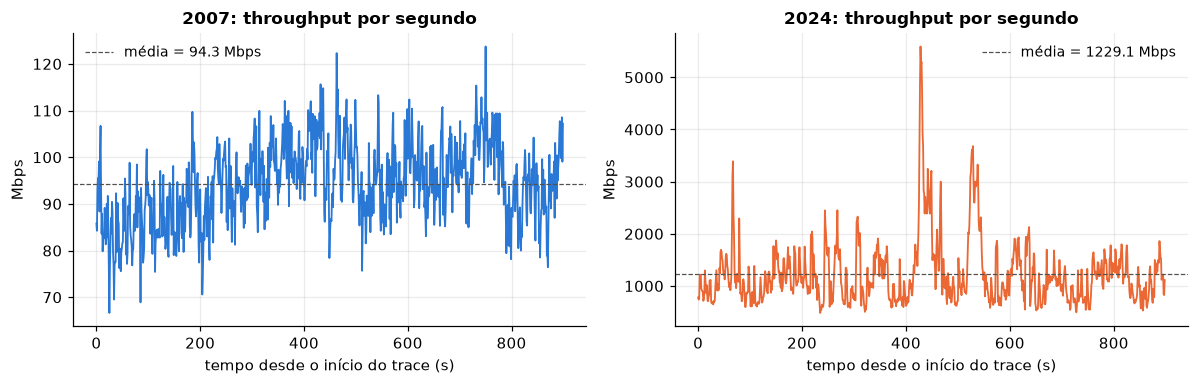

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, ano in zip(axs, D):
    v = vazao(ano, 1000)                                   # Mbps, 1 ponto por segundo
    ax.plot(v.index, v.values, color=COR[ano])
    ax.axhline(v.mean(), color='#52514e', lw=0.8, ls='--', label=f'média = {v.mean():.1f} Mbps')
    ax.set_title(f'{ano}: throughput por segundo')
    ax.set_xlabel('tempo desde o início do trace (s)'); ax.set_ylabel('Mbps'); ax.legend()
plt.tight_layout(); plt.show()

### Exemplo E3 · Estatísticas descritivas — exemplo

**Objetivo:** Calcular as estatísticas do throughput **total de 2007** (a 1 s). Na tarefa T1 você completa para os dois anos e para TCP e UDP.

In [10]:
v2007 = vazao('2007', 1000)            # pd.Series: throughput em Mbps, 1 valor por segundo
sd2007 = v2007.describe().round(2).to_frame('2007 · total (Mbps)')
display(sd2007)

,2007 · total (Mbps)
count,900.00
mean,94.29
std,8.58
min,66.64
25%,88.41
50%,94.37
75%,99.86
max,123.73


## 4. Tarefas

### Tarefa T1 · Estatísticas descritivas

**Objetivo:** Montar **uma tabela** com **média, desvio-padrão, mínimo, quartis (Q1, mediana, Q3) e máximo** do throughput por segundo (Mbps), para **2007 e 2024**, separando o tráfego **total**, **TCP** e **UDP**.

**Dados:** `vazao(ano, 1000, coluna)` devolve o throughput em Mbps (1 valor por segundo) como `pd.Series`; `coluna` é `bytes` (total), `bytes_tcp` ou `bytes_udp`.

**Dicas:**

* `Series.describe()` já calcula quase tudo (média, desvio, mínimo, quartis, máximo).
* Monte um dicionário com chaves `(ano, série)` e converta para `pd.DataFrame`: as colunas ficam agrupadas por ano.

In [15]:
SERIES = {'Total': 'bytes', 'TCP': 'bytes_tcp', 'UDP': 'bytes_udp'}     # nome -> coluna usada em vazao(ano, 1000, coluna)

# TODO: monte a tabela com colunas (ano, série) e linhas: média, desvio-padrão, mínimo, Q1, mediana, Q3, máximo
#       (Mbps, escala de 1 s) e exiba com display(tabela.round(2))

anos = ['2007', '2024']

#dicionario (ano, serie) -> pd.Series
dicionario_tabela = {}
for ano in anos:
    for serie, coluna in SERIES.items():
        s = vazao(ano, 1000, coluna)
        dados = s.describe()
        dados = dados.drop(['count'])  # descartar count que nao eh mt util nem pedido
        dicionario_tabela[(ano, serie)] = dados

tabela = pd.DataFrame(dicionario_tabela)
display(tabela.round(2))

2007                   2024                 
       Total     TCP   UDP    Total      TCP     UDP
mean   94.29   91.63  2.01  1229.11  1082.42   96.74
std     8.58    8.54  0.33   626.23   627.09   33.26
min    66.64   64.09  1.40   483.00   358.21   46.88
25%    88.41   85.88  1.81   818.46   677.27   73.77
50%    94.37   91.66  1.92  1091.54   937.85   91.34
75%    99.86   97.14  2.10  1454.95  1313.89  110.94
max   123.73  121.41  5.15  5591.12  5442.49  343.38

### Tarefa T2 · Gráfico 2 — Histogramas do throughput por protocolo (TCP × UDP)

**Objetivo:** Para cada ano (2007 à esquerda, 2024 à direita), plotar a distribuição do throughput por segundo (Mbps) de **TCP** e de **UDP** no mesmo gráfico.

**Dados:** `vazao(ano, 1000, coluna)` com `coluna` = `bytes_tcp` ou `bytes_udp`.

**Dicas:**

* `ax.hist(serie, bins=40, alpha=0.65, label=...)` permite sobrepor dois histogramas.
* Use as cores de `COR_PROTO` (`COR_PROTO["TCP"]`, `COR_PROTO["UDP"]`).
* Coloque a média de cada protocolo na legenda; use título, rótulos nos eixos e legenda.

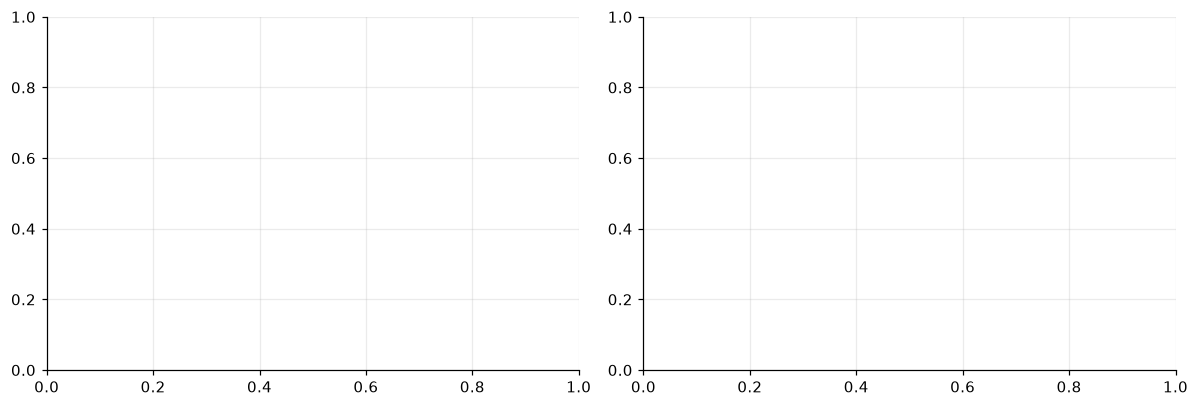

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
# TODO: em cada gráfico (um por ano) sobreponha os histogramas de TCP e UDP
#       (vazao(ano, 1000, 'bytes_tcp') e vazao(ano, 1000, 'bytes_udp')), com título, rótulos dos eixos e legenda

v2007 = {
    'TCP': vazao('2007', 1000, 'bytes_tcp'),
    'UDP': vazao('2007', 1000, 'bytes_udp')
}

v2024 = {
    'TCP': vazao('2024', 1000, 'bytes_tcp'),
    'UDP': vazao('2024', 1000, 'bytes_udp')
}

for ax, ano in zip(axs, D):
    v = vazao(ano, 1000)                                   # Mbps, 1 ponto por segundo
    ax.plot(v.index, v.values, color=COR[ano])
    ax.hist([v2007['TCP'], v2007['UDP']] if ano == '2007' else [v2024['TCP'], v2024['UDP']],
            bins=50, alpha=0.65, label=['TCP', 'UDP'], color=[COR_PROTO['TCP'], COR_PROTO['UDP']])
    ax.set_title(f'{ano}: throughput por segundo')
    ax.set_xlabel('tempo desde o início do trace (s)'); ax.set_ylabel('Mbps'); ax.legend()

plt.tight_layout(); plt.show()

### Tarefa T3 · Gráfico 3 — Distribuição do tamanho dos pacotes por protocolo

**Objetivo:** Para cada ano (2007 à esquerda, 2024 à direita), plotar o histograma do **tamanho dos pacotes** de **TCP** e de **UDP** (em % dos pacotes de cada protocolo).

**Dados:** `D[ano].tam` é uma tabela com as colunas `tipo` (TCP, UDP, ...), `tamanho` (bytes) e `pacotes` (quantos pacotes têm esse tamanho). Ela já é um histograma exato: use-a como **pesos**.

**Dicas:**

* Filtre `D[ano].tam[D[ano].tam["tipo"] == "TCP"]` e some `pacotes` por `tamanho` (`groupby`).
* `np.histogram(tamanhos, bins=bins, weights=pacotes)` constrói o histograma ponderado; use `bins = np.arange(0, 1601, 50)`.
* Divida por `h.sum()` e multiplique por 100 para ter % dos pacotes do protocolo; desenhe com `ax.bar(...)`, colocando TCP e UDP **lado a lado** (largura 25, UDP deslocado de 25 B) para que um não esconda o outro.

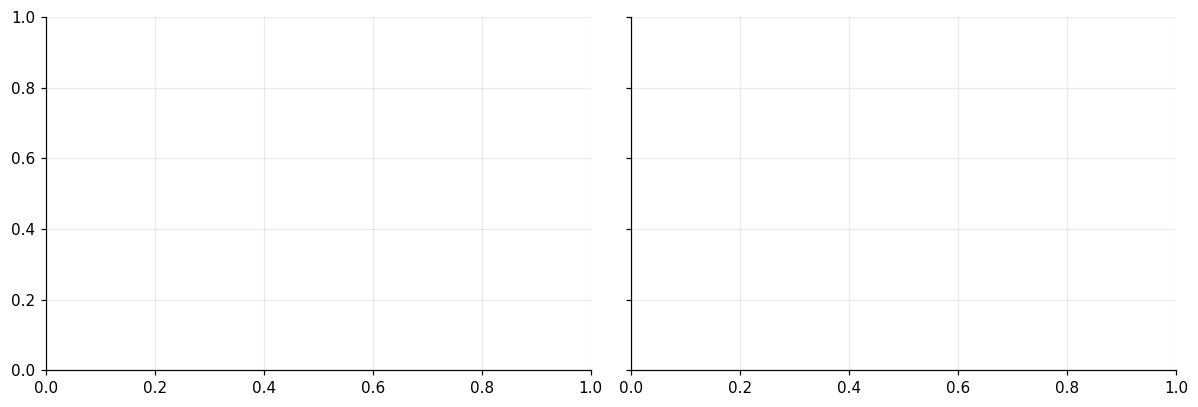

In [ ]:
bins = np.arange(0, 1601, 50)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
# TODO: em cada gráfico (um por ano), histograma ponderado do tamanho dos pacotes TCP e UDP (em % dos pacotes do protocolo)
#       com título, rótulos dos eixos e legenda
plt.tight_layout(); plt.show()